In [1]:
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.analysis.DataAnalyzer import DataAnalyzer
from anomalouslib.models.model_handler import load_model
from anomalouslib.data.preprocessing import generate_classification_tensors
from anomalouslib.analysis.DataAnalyzer import DataAnalyzer
from anomalouslib.constants import trajectory_types_mapping
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np
import torch

In [13]:
model= load_model("./FractionalBrownianMotionHurstRegressor.pth")

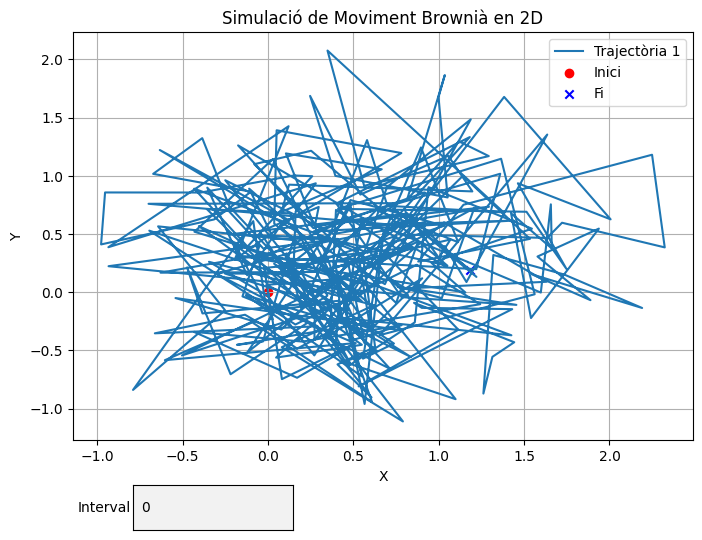

In [33]:
traj = DatasetGenerator(num_particules=1).generate_FractionalBrownianMotion(num_passos=300, hurst=0.1)
DataAnalyzer(traj).mostrar_trajectories()

In [11]:
traj["attributes"][0]["trajectory_type"] = {
    0: "Brownian Motion",
    50: "Annealed Transient Time Model",
    100: "Lévy Walk",
    150: "Scaled Brownian Motion"
}

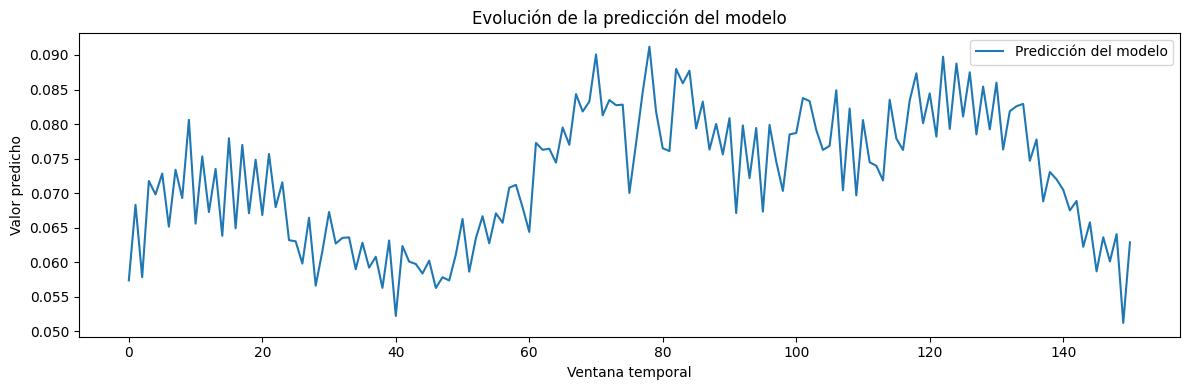

In [34]:
def analyze_continuous_trajectory_patterns(model, traj, parm_to_eval, traj_pos=0, window_size=150):
    dataframe = traj.iloc[[traj_pos]].copy()
    dataframe = dataframe.sample(frac=1).reset_index(drop=True)

    # Tractem les coordenades per aconseguir X_tensor
    coords_list = [np.stack([row[0], row[1]], axis=1) for row in dataframe['coords']]
    X = np.array(coords_list)  # Forma (n_samples, seq_length, 2)
    X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)

    params = dataframe["attributes"].apply(lambda x: x[parm_to_eval])[0]

    def get_correct_type(diccionario, valor):
        claves_ordenadas = sorted(diccionario.keys())
        for i in range(len(claves_ordenadas)):
            inicio = claves_ordenadas[i]
            fin = claves_ordenadas[i + 1] if i + 1 < len(claves_ordenadas) else float('inf')
            if inicio <= valor < fin:
                return diccionario[inicio]
        return None

    X_unfolded = X_tensor.unfold(dimension=2, size=window_size, step=1)
    X_windows = X_unfolded.permute(2, 0, 1, 3)
    X_list = [x for x in X_windows]

    X_adjusted = []
    for window in X_list:
        start = window[:, :, 0].unsqueeze(-1)
        adjusted = window - start
        X_adjusted.append(adjusted)

    model.eval()
    predictions = []
    with torch.no_grad():
        for x in X_adjusted:
            pred = model(x)
            predictions.append(pred.item())

    predictions = np.array(predictions)

    # Graficar la predicción del modelo
    plt.figure(figsize=(12, 4))
    plt.plot(predictions, label='Predicción del modelo')
    plt.title('Evolución de la predicción del modelo')
    plt.xlabel('Ventana temporal')
    plt.ylabel('Valor predicho')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return predictions

outputs = analyze_trajectory_patterns(model, traj, "trajectory_type")


In [136]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Generar dos trayectorias de tipos diferentes y concatenarlas
dg = DatasetGenerator(num_particules=1)
traj1 = dg.generate_FractionalBrownianMotion(num_passos=300, random_params=True)
traj2 = dg.generate_LevyWalks(num_passos=400, alpha=1.5, beta=0.75, speed=2)
traj3 = dg.generate_BrownianMotion(num_passos=300, sigma=3, delta_t=0.5)

# Concatenar las trayectorias
traj_concat = traj1.copy()
# Obtener el último valor de traj1
last_coords_traj1 = np.array(traj1.iloc[0]["coords"])
last_point = last_coords_traj1[:, -1]

# Obtener los valores de traj2 y sumarle el último punto de traj1
coords_traj2 = np.array(traj2.iloc[0]["coords"])
coords_traj2_shifted = coords_traj2 + last_point[:, None]

# Concatenar las coordenadas
coords_concat = np.concatenate([last_coords_traj1, coords_traj2_shifted], axis=1)

# Obtener el último valor de traj1
last_point2 = coords_concat[:, -1]

# Obtener los valores de traj3 y sumarle el último punto de traj2
coords_traj3 = np.array(traj3.iloc[0]["coords"])
coords_traj3_shifted = coords_traj3 + last_point2[:, None]

# Concatenar las coordenadas
coords_concat = np.concatenate([coords_concat, coords_traj3_shifted], axis=1)

# Actualizar el DataFrame concatenado
traj_concat.at[0, "coords"] = coords_concat.tolist()
traj_concat.at[0, "num_steps"] = coords_concat.shape[1]
# traj_concat.at[0, "trajectory_type"] = traj1.iloc[0]["trajectory_type"] + "+" + traj2.iloc[0]["trajectory_type"]
traj_concat.at[0, "attributes"] = {
    "trajectory_type": {
        0: "Fractional Brownian Motion",
        300: "Lévy Walk",
        700: "Brownian Motion"
    }
}
traj = traj_concat

c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousLab\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


In [88]:
trajectory_types_mapping["Annealed Transient Time Model"].__name__

'attm'

In [92]:
valores = le.inverse_transform(np.arange(outputs.shape[1]))
mapping = np.array([trajectory_types_mapping[valor].__name__ for valor in valores])
mapping

array(['attm', 'bm', 'ctrw', 'fbm', 'lw', 'rw', 'sbm'], dtype='<U4')

In [95]:
mapping[0]

np.str_('attm')